## Bagging and Pasting

## Bagging and Pasting in Scikit-Learn

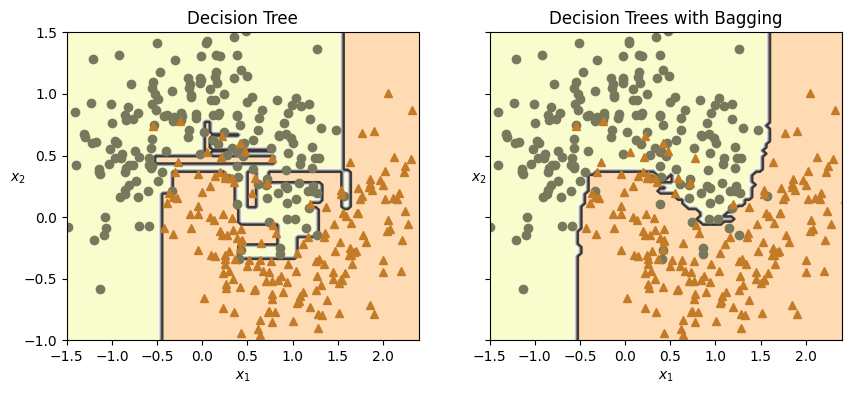

In [2]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

def plot_decision_boundary(clf, X, y, alpha=1.0):
    axes = [-1.5, 2.4, -1, 1.5]                     # рамка: x слева/справа, y снизу/сверху
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                         np.linspace(axes[2], axes[3], 100))   # шахматка 100x100
    X_new = np.c_[x1.ravel(), x2.ravel()]            # 10000 точек в таблицу 2 колонки
    y_pred = clf.predict(X_new).reshape(x1.shape)    # класс 0/1 для каждой клетки

    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap='Wistia')  # фон (раскраска)
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8)    # линии границ

    colors = ["#78785c", "#c47b27"]
    markers = ("o", "^")
    for idx in (0, 1):                               # точки данных, 2 класса
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx],
                 color=colors[idx], marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# A BaggingClassifier automatically performs soft voting instead of hard voting
bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,
max_samples=100, n_jobs=-1, random_state=42)
bag_clf.fit(X_train, y_train)

# Default decision tree classifier
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)                       # одно дерево, весь train

fig, ax = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(ax[0])                                       # переключиться на левый график
plot_decision_boundary(tree_clf, X_train, y_train)
plt.title("Decision Tree")
plt.sca(ax[1])                                       # правый график
plot_decision_boundary(bag_clf, X_train, y_train)    # твой bag_clf из предыдущей ячейки
plt.title("Decision Trees with Bagging")
plt.show()



## Out-of-Bag Evaluation

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,
 n_jobs=-1, random_state=42, oob_score=True)
bag_clf.fit(X_train, y_train)

print(len(X_train))
# Тут оценка слегка заниженная и пессимистичная 
print(bag_clf.oob_score_)

y_pred = bag_clf.predict(X_test)
# Если посмотреть, то на самом деле лучше
print(accuracy_score(y_test, y_pred))

# OOB decision function — вероятности для каждого train-инстанса
# доступны в атрибуте oob_decision_function_ (после fit)
# работает, если у базового estimator есть predict_proba()
# строки = инстансы, столбцы = [P(класс 0), P(класс 1)]
# инстанс 1: 67.6% класс 1 (позитив), 32.4% класс 0 (негатив)
# считают только деревья, которые этот инстанс НЕ видели (те же ~37%)
# oob_score_ = accuracy по argmax этих же вероятностей
print(bag_clf.oob_decision_function_[:3]) # probas for the first 3 instances

375
0.896
0.92
[[0.32352941 0.67647059]
 [0.3375     0.6625    ]
 [1.         0.        ]]


## Random Patches and Random Subspaces